# Discontinuous Galerkin for Poisson

This tutorial treats the symmetric interior penalty (SIPG) discretisation of the Poisson
equation, in the spirit of the DG material in the
[FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/) and the
[DOLFINx demos](https://docs.fenicsproject.org/dolfinx/main/python/demos.html).
We solve

$$ -\Delta u = f \ \text{in } \Omega=(0,1)^2, \qquad u = g \ \text{on } \partial\Omega $$

with piecewise polynomials that are discontinuous across elements.  With the jump
$[\![w]\!] = w^+ n^+ + w^- n^-$ and the average $\{w\} = (w^+ + w^-)/2$ the method reads:
find $u_h \in V_h$ such that

$$
\begin{aligned}
&\int_\Omega \nabla u_h\cdot\nabla v_h\,dx
 - \int_{\mathcal F_i} \{\nabla u_h\}\cdot[\![v_h]\!] + [\![u_h]\!]\cdot\{\nabla v_h\} \,dS
 + \int_{\mathcal F_i} \frac{\alpha}{\{h\}} [\![u_h]\!]\cdot[\![v_h]\!]\,dS \\
&\quad - \int_{\partial\Omega} \partial_n u_h\, v_h + u_h\,\partial_n v_h \,ds
 + \int_{\partial\Omega} \frac{\alpha}{h}\, u_h v_h\,ds
 = \int_\Omega f v_h\,dx - \int_{\partial\Omega} g\,\partial_n v_h\,ds + \int_{\partial\Omega} \frac{\alpha}{h}\, g\, v_h\,ds .
\end{aligned}
$$

The boundary terms are Nitsche's way of imposing $u=g$ weakly, so there is no
`DirichletBC`.  The penalty parameter $\alpha$ has to grow with the polynomial degree $k$;
we use $\alpha = 10\,k^2$.

## Forms

The interior facet terms are written with the UFL operators `jump`, `avg`, `FacetNormal`
and `CellDiameter`, integrated with `dS`.  ngsufl maps `dS` to NGSolve's skeleton
integrals (`dx(skeleton=True)`), and `ds` to boundary integrals.

In [1]:
from ngsufl import *
import numpy as np

def solve_sipg(n, k):
    mesh = UnitSquareMesh(n, n)
    V = FunctionSpace(mesh, "DG", k)
    u, v = TrialFunction(V), TestFunction(V)
    x = SpatialCoordinate(mesh)
    nrm, h = FacetNormal(mesh), CellDiameter(mesh)
    h_avg = avg(h)
    alpha = Constant(10.0 * k**2)

    u_e = sin(2 * pi * x[0]) * cos(pi * x[1]) + x[0] * x[1]
    f = -div(grad(u_e))

    a = (inner(grad(u), grad(v)) * dx
         - inner(avg(grad(u)), jump(v, nrm)) * dS
         - inner(jump(u, nrm), avg(grad(v))) * dS
         + alpha / h_avg * inner(jump(u, nrm), jump(v, nrm)) * dS
         - inner(grad(u), nrm) * v * ds
         - u * inner(grad(v), nrm) * ds
         + alpha / h * u * v * ds)
    L = (f * v * dx
         - u_e * inner(grad(v), nrm) * ds
         + alpha / h * u_e * v * ds)

    uh = Function(V, name="u")
    solve(a == L, uh)
    return mesh, u_e, uh

mesh, u_e, uh = solve_sipg(8, 2)
print("dofs:", uh.function_space().dim())
print("L2 error:", errornorm(u_e, uh))
print("H1 error:", errornorm(u_e, uh, "H1"))

dofs: 768
L2 error: 0.001570127285175526
H1 error: 0.10716693667795905


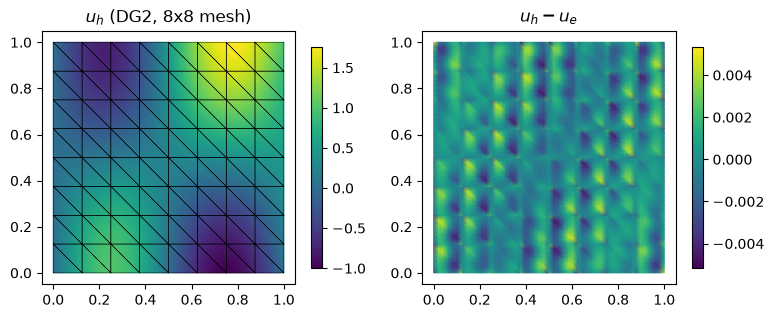

In [2]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
plot(uh, ax=axs[0], subdivision=6)
plot(mesh, ax=axs[0], lw=0.3)
axs[0].set_title("$u_h$ (DG2, 8x8 mesh)")
plot(uh - u_e, ax=axs[1], subdivision=6)
axs[1].set_title("$u_h - u_e$");

The solution is only weakly coupled across facets, which is visible in the plot of the
error on the right: it is allowed to jump from element to element.

## Convergence

For degree $k$ one expects $\|u-u_h\|_{L^2} = O(h^{k+1})$.  The $H^1$ error here is the broken
one: the gradient is taken element by element.

In [3]:
def rates(errs, hs):
    return [np.log(errs[i] / errs[i + 1]) / np.log(hs[i] / hs[i + 1]) for i in range(len(errs) - 1)]

ns = [4, 8, 16, 32]
hs = [1 / n for n in ns]
errs = {}
for k in [1, 2, 3]:
    errs[k] = [errornorm(ue, uh) for _, ue, uh in (solve_sipg(n, k) for n in ns)]
    print(f"k={k}  L2 errors", " ".join(f"{e:.2e}" for e in errs[k]),
          "  rates", " ".join(f"{r:.2f}" for r in rates(errs[k], hs)))

k=1  L2 errors 7.92e-02 2.52e-02 6.92e-03 1.79e-03   rates 1.65 1.86 1.95
k=2  L2 errors 1.22e-02 1.57e-03 1.99e-04 2.51e-05   rates 2.96 2.98 2.99


k=3  L2 errors 1.66e-03 1.05e-04 6.58e-06 4.11e-07   rates 3.97 4.00 4.00


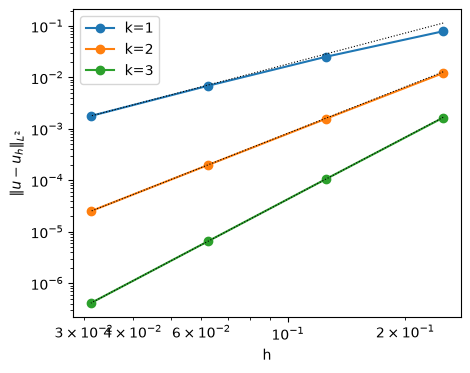

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
for k, e in errs.items():
    ax.loglog(hs, e, "o-", label=f"k={k}")
    ax.loglog(hs, [e[-1] * (h / hs[-1]) ** (k + 1) for h in hs], "k:", lw=0.8)
ax.set_xlabel("h")
ax.set_ylabel(r"$\|u-u_h\|_{L^2}$")
ax.legend();

## Consistency and symmetry

The scheme is consistent: if the exact solution lies in $V_h$ it is reproduced.  We test
this with a polynomial of degree 2 and $k=2$.  A second property of the symmetric method
is that the discrete problem is symmetric, which we verify on the assembled matrix.

In [5]:
mesh = UnitSquareMesh(6, 6)
V = FunctionSpace(mesh, "DG", 2)
u, v = TrialFunction(V), TestFunction(V)
x = SpatialCoordinate(mesh)
nrm, h = FacetNormal(mesh), CellDiameter(mesh)
alpha = Constant(40.0)
a = (inner(grad(u), grad(v)) * dx
     - inner(avg(grad(u)), jump(v, nrm)) * dS - inner(jump(u, nrm), avg(grad(v))) * dS
     + alpha / avg(h) * inner(jump(u, nrm), jump(v, nrm)) * dS
     - inner(grad(u), nrm) * v * ds - u * inner(grad(v), nrm) * ds + alpha / h * u * v * ds)
p = 1 + x[0] ** 2 - x[0] * x[1] + 2 * x[1] ** 2
L = (-div(grad(p)) * v * dx - p * inner(grad(v), nrm) * ds + alpha / h * p * v * ds)
uh = Function(V)
solve(a == L, uh)
print("reproduction error:", errornorm(p, uh))

A = assemble(a)
import scipy.sparse as sp
rows, cols, vals = A.COO()
M = sp.coo_matrix((vals, (rows, cols))).tocsr()
print("max |A - A^T|     :", abs(M - M.T).max(), "  max |A| :", abs(M).max())

reproduction error: 1.0255527913737032e-14
max |A - A^T|     : 1.4210854715202004e-14   max |A| : 96.56854249492355
